# Arquiteturas Híbridas (Conv1D + GRU/LSTM) aplicadas a Séries Temporais

Implementação e avaliação de modelos híbridos combinando convolução unidimensional (**Conv1D**) e redes recorrentes (**GRU** e **LSTM**) para a previsão de resultados em séries temporais.

### Etapas:

1. **Preparação dos Dados:** Estruturação das janelas temporais no formato tridimensional **NTC** (*Amostras, Passos Temporais, Canais*) com divisão cronológica e normalização.
2. **Modelagem:** Construção das arquiteturas híbridas **Conv1D + GRU** e **Conv1D + LSTM**, utilizando extração local de características seguida de modelagem sequencial (*Sequence-to-Vector*).
3. **Treinamento e Avaliação:** Ajuste dos modelos, análise das curvas de aprendizado e comparação de desempenho frente às abordagens anteriores.

In [1]:
import pandas as pd

# Configuração para reprodutibilidade
SEED = 42

# Carregamento do dataset
DATASET_PATH = "../data/team-time-series-10000.xlsx"

df = pd.read_excel(DATASET_PATH)

print(f"Seed definida: {SEED}")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")

display(df.head())

Seed definida: 42
Dimensões do dataset: 289264 linhas e 108 colunas


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [2]:
# Filtragem dos primeiros 20 minutos (inclusive)
df_filtrado = df[df["timestep"].between(0, 20)].copy()

print(f"Dimensões após filtragem: {df_filtrado.shape}")
print(f"Partidas encontradas: {df_filtrado['match_id'].nunique()}")
print(f"Timesteps encontrados: {sorted(df_filtrado['timestep'].unique())}")

display(df_filtrado.head())

Dimensões após filtragem: (210000, 108)
Partidas encontradas: 10000
Timesteps encontrados: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


,match_id,timestep,vencedor,blue_championStats.abilityHaste,blue_championStats.abilityPower,blue_championStats.armor,blue_championStats.attackDamage,blue_championStats.health,blue_currentGold,blue_damageStats.magicDamageDone,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3258230874,0,200,0,0,151,278,3080,2100,0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3258230874,1,200,0,9,151,318,3559,0,15,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3258230874,2,200,0,9,166,329,3135,1846,304,...,1,-1,1,0,0,0,0,0,0,0
3,BR1_3258230874,3,200,0,9,190,375,3290,1776,1777,...,1,-1,1,0,0,0,0,0,0,0
4,BR1_3258230874,4,200,0,9,217,388,3159,3219,3237,...,1,-1,1,0,0,0,0,0,0,0


In [3]:
# Identificação das colunas de entrada
feature_cols = [
    col for col in df_filtrado.columns
    if col.startswith(("blue_", "red_", "diff_"))
]

# Separação das características e do vencedor
X = df_filtrado[feature_cols]
y = df_filtrado["vencedor"]

print(f"Quantidade de características: {len(feature_cols)}")
print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")

print("\nDistribuição dos vencedores:")
print(y.value_counts())

Quantidade de características: 105
Dimensões de X: (210000, 105)
Dimensões de y: (210000,)

Distribuição dos vencedores:
vencedor
200    113379
100     96621
Name: count, dtype: int64


In [4]:
# Verificação da quantidade de registros por partida
registros_por_partida = df_filtrado.groupby("match_id").size()

# Verificação da consistência do vencedor
vencedores_por_partida = df_filtrado.groupby("match_id")["vencedor"].nunique()

print(f"Partidas com exatamente 21 registros: {(registros_por_partida == 21).sum()}")
print(f"Partidas com exatamente um vencedor: {(vencedores_por_partida == 1).sum()}")

print(f"Menor quantidade de registros: {registros_por_partida.min()}")
print(f"Maior quantidade de registros: {registros_por_partida.max()}")

Partidas com exatamente 21 registros: 10000
Partidas com exatamente um vencedor: 10000
Menor quantidade de registros: 21
Maior quantidade de registros: 21


In [5]:
import numpy as np

# Ordenação cronológica dos registros
df_filtrado = df_filtrado.sort_values(
    by=["match_id", "timestep"]
).reset_index(drop=True)

# Recuperação das características após a ordenação
X = df_filtrado[feature_cols].to_numpy()

# Quantidade de partidas
n_partidas = df_filtrado["match_id"].nunique()

# Transformação: partidas × instantes × características
X = X.reshape(n_partidas, 21, len(feature_cols))

# Um único vencedor por partida
y = df_filtrado.groupby("match_id", sort=False)["vencedor"].first().to_numpy()

print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")

Dimensões de X: (10000, 21, 105)
Dimensões de y: (10000,)


In [6]:
# Índices para divisão cronológica
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Separação dos conjuntos
X_train, y_train = X[:train_end], y[:train_end]

X_val, y_val = X[train_end:val_end], y[train_end:val_end]

X_test, y_test = X[val_end:], y[val_end:]

print("Treinamento:", X_train.shape, y_train.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_test.shape, y_test.shape)

Treinamento: (7000, 21, 105) (7000,)
Validação: (1500, 21, 105) (1500,)
Teste: (1500, 21, 105) (1500,)


In [7]:
from sklearn.preprocessing import StandardScaler

# Inicialização do normalizador
scaler = StandardScaler()

# Recuperação das dimensões
n_train, timesteps, n_features = X_train.shape
n_val = X_val.shape[0]
n_test = X_test.shape[0]

# Transformação temporária para duas dimensões
X_train_2d = X_train.reshape(-1, n_features)

# Ajuste e normalização do treinamento
X_train_scaled = scaler.fit_transform(X_train_2d)

# Normalização da validação e do teste usando os parâmetros do treinamento
X_val_scaled = scaler.transform(X_val.reshape(-1, n_features))
X_test_scaled = scaler.transform(X_test.reshape(-1, n_features))

# Recuperação do formato tridimensional
X_train = X_train_scaled.reshape(n_train, timesteps, n_features)
X_val = X_val_scaled.reshape(n_val, timesteps, n_features)
X_test = X_test_scaled.reshape(n_test, timesteps, n_features)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (7000, 21, 105)
Validação: (1500, 21, 105)
Teste: (1500, 21, 105)


In [8]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configuração para reprodutibilidade
tf.keras.utils.set_random_seed(SEED)

print(f"TensorFlow: {tf.__version__}")

TensorFlow: 2.21.0


### Construção da CNN+LSTM

Os dados foram preparados, normalizados e divididos em conjuntos de treino, validação e teste.

Agora, será construída uma arquitetura híbrida CNN+LSTM, combinando a extração de características da CNN com a capacidade de aprendizado temporal da LSTM.

In [10]:
# Dimensões da entrada
num_features = X_train.shape[2]
win_size = X_train.shape[1]

# Construção da CNN-1D + LSTM
model_cnn_lstm = keras.Sequential([
    layers.Input(shape=(win_size, num_features)),

    # Primeira camada convolucional
    layers.Conv1D(
        filters=32,
        kernel_size=3,
        strides=2,
        padding="valid",
        activation="relu"
    ),

    # Segunda camada convolucional
    layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),

    # Camada LSTM para aprendizado das dependências temporais
    layers.LSTM(64),

    # Camada totalmente conectada
    layers.Dense(64, activation="relu"),

    # Saída para classificação binária
    layers.Dense(1, activation="sigmoid")

], name="CNN1D_LSTM_LeagueOfLegends")

model_cnn_lstm.summary()

Model: "CNN1D_LSTM_LeagueOfLegends"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 10, 32)         │        10,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,569 (209.25 KB)

 Trainable params: 53,569 (209.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Conversão dos rótulos para classificação binária
y_train = (y_train == 200).astype("float32")
y_val = (y_val == 200).astype("float32")
y_test = (y_test == 200).astype("float32")

print("Distribuição dos rótulos de treinamento:")
print(pd.Series(y_train).value_counts().sort_index())

Distribuição dos rótulos de treinamento:
0.0    3223
1.0    3777
Name: count, dtype: int64


In [12]:
# Compilação da CNN-1D + LSTM
model_cnn_lstm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Interrompe o treinamento caso a validação não melhore
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [13]:
# Treinamento da CNN-1D + LSTM
history_cnn_lstm = model_cnn_lstm.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7437 - loss: 0.5111 - val_accuracy: 0.7773 - val_loss: 0.4720
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7656 - loss: 0.4783 - val_accuracy: 0.7740 - val_loss: 0.4693
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7721 - loss: 0.4711 - val_accuracy: 0.7760 - val_loss: 0.4655
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7743 - loss: 0.4652 - val_accuracy: 0.7800 - val_loss: 0.4641
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7773 - loss: 0.4595 - val_accuracy: 0.7760 - val_loss: 0.4643
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7816 - loss: 0.4539 - val_accuracy: 0.7780 - val_loss: 0.4649
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7846 - loss: 0.4475 - val_accuracy: 0.7747 - val_loss: 0.4703


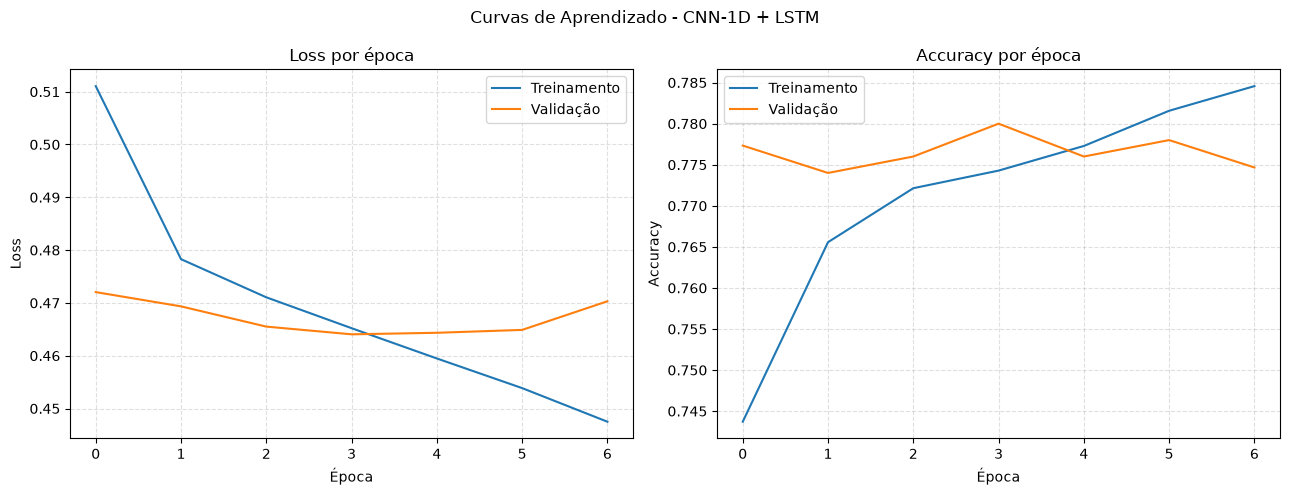

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva de Loss
axes[0].plot(
    history_cnn_lstm.history["loss"],
    label="Treinamento"
)

axes[0].plot(
    history_cnn_lstm.history["val_loss"],
    label="Validação"
)

axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Curva de Accuracy
axes[1].plot(
    history_cnn_lstm.history["accuracy"],
    label="Treinamento"
)

axes[1].plot(
    history_cnn_lstm.history["val_accuracy"],
    label="Validação"
)

axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.suptitle("Curvas de Aprendizado - CNN-1D + LSTM")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Probabilidades previstas pela CNN+LSTM
y_val_prob = model_cnn_lstm.predict(X_val)

# Conversão das probabilidades em classes (limiar 0.5)
y_val_pred = (y_val_prob >= 0.5).astype(int).ravel()

# Cálculo das métricas
accuracy = accuracy_score(y_val, y_val_pred)
f1_macro = f1_score(y_val, y_val_pred, average="macro")
balanced_acc = balanced_accuracy_score(y_val, y_val_pred)

print(f"Accuracy:          {accuracy:.4f}")
print(f"F1 Macro:          {f1_macro:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_val_pred))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Accuracy:          0.7800
F1 Macro:          0.7733
Balanced Accuracy: 0.7707

Matriz de confusão:
[[456 224]
 [106 714]]


In [17]:
# Probabilidades previstas pela CNN+LSTM no conjunto de teste
y_test_prob = model_cnn_lstm.predict(X_test)

# Conversão das probabilidades em classes (limiar 0.5)
y_test_pred = (y_test_prob >= 0.5).astype(int).ravel()

# Cálculo das métricas
accuracy_test = accuracy_score(y_test, y_test_pred)
f1_macro_test = f1_score(y_test, y_test_pred, average="macro")
balanced_acc_test = balanced_accuracy_score(y_test, y_test_pred)

print("=" * 50)
print("AVALIAÇÃO - CNN-1D + LSTM (CONJUNTO DE TESTE)")
print("=" * 50)

print(f"Accuracy:          {accuracy_test:.4f}")
print(f"F1 Macro:          {f1_macro_test:.4f}")
print(f"Balanced Accuracy: {balanced_acc_test:.4f}")

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
AVALIAÇÃO - CNN-1D + LSTM (CONJUNTO DE TESTE)
Accuracy:          0.7613
F1 Macro:          0.7567
Balanced Accuracy: 0.7554


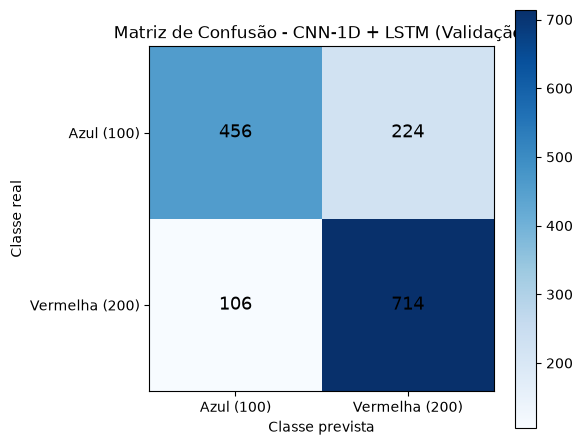

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcula a matriz de confusão
cm = confusion_matrix(y_val, y_val_pred)

# Visualização
plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Matriz de Confusão - CNN-1D + LSTM (Validação)")
plt.colorbar()

# Rótulos dos eixos
classes = ["Azul (100)", "Vermelha (200)"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

# Valores dentro das células
for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=13
        )

plt.tight_layout()
plt.show()

### Construção da CNN+GRU

Os dados já foram preparados, normalizados e divididos em conjuntos de treino, validação e teste, além da implementação e teste da arquitetura híbrida CNN+LSTM.

Agora, será construída uma arquitetura híbrida CNN+GRU, combinando a extração de características da CNN com a capacidade de aprendizado temporal da GRU.

In [19]:
# Dimensões da entrada
num_features = X_train.shape[2]
win_size = X_train.shape[1]

# Construção da CNN-1D + GRU
model_cnn_gru = keras.Sequential([
    layers.Input(shape=(win_size, num_features)),

    # Primeira camada convolucional
    layers.Conv1D(
        filters=32,
        kernel_size=3,
        strides=2,
        padding="valid",
        activation="relu"
    ),

    # Segunda camada convolucional
    layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu"
    ),

    # Camada GRU para aprendizado das dependências temporais
    layers.GRU(64),

    # Camada totalmente conectada
    layers.Dense(64, activation="relu"),

    # Saída para classificação binária
    layers.Dense(1, activation="sigmoid")

], name="CNN1D_GRU_LeagueOfLegends")

model_cnn_gru.summary()

Model: "CNN1D_GRU_LeagueOfLegends"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 10, 32)         │        10,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 10, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,505 (177.75 KB)

 Trainable params: 45,505 (177.75 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Compilação da CNN-1D + GRU
model_cnn_gru.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Interrompe o treinamento caso a validação não melhore
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [21]:
# Treinamento da CNN-1D + GRU
history_cnn_gru = model_cnn_gru.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7511 - loss: 0.5091 - val_accuracy: 0.7693 - val_loss: 0.4702
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7687 - loss: 0.4771 - val_accuracy: 0.7767 - val_loss: 0.4655
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7739 - loss: 0.4690 - val_accuracy: 0.7753 - val_loss: 0.4659
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7746 - loss: 0.4637 - val_accuracy: 0.7780 - val_loss: 0.4632
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7779 - loss: 0.4564 - val_accuracy: 0.7787 - val_loss: 0.4594
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7830 - loss: 0.4516 - val_accuracy: 0.7787 - val_loss: 0.4580
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7819 - loss: 0.4451 - val_accuracy: 0.7793 - val_loss: 0.4614
Epoch 8/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7871 - loss: 0.4375 - val_accuracy: 0.

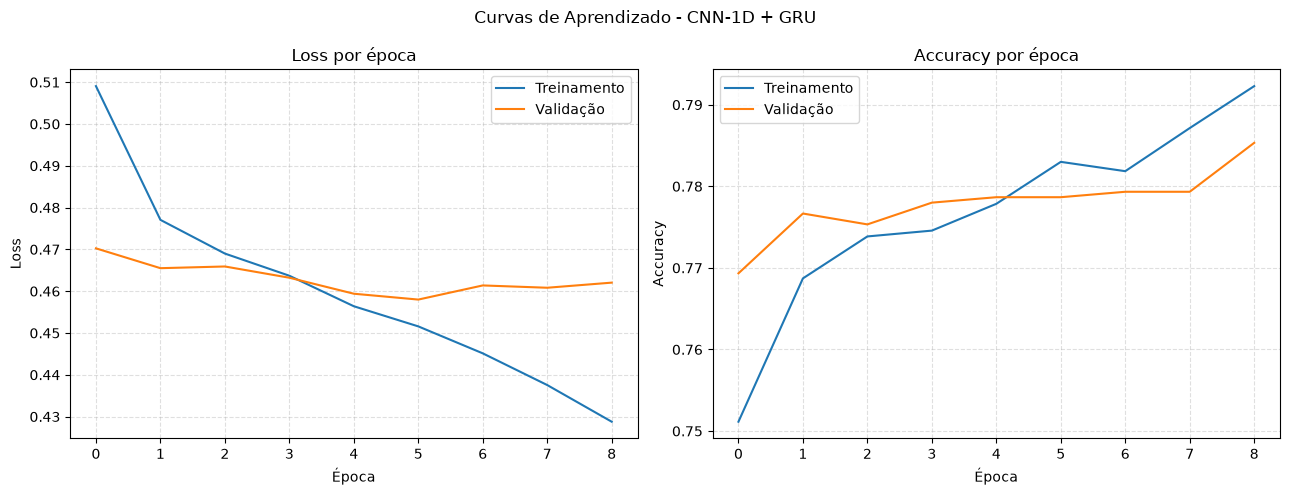

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva de Loss
axes[0].plot(
    history_cnn_gru.history["loss"],
    label="Treinamento"
)

axes[0].plot(
    history_cnn_gru.history["val_loss"],
    label="Validação"
)

axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Curva de Accuracy
axes[1].plot(
    history_cnn_gru.history["accuracy"],
    label="Treinamento"
)

axes[1].plot(
    history_cnn_gru.history["val_accuracy"],
    label="Validação"
)

axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.suptitle("Curvas de Aprendizado - CNN-1D + GRU")
plt.tight_layout()
plt.show()

In [23]:
# Probabilidades previstas pela CNN+GRU
y_val_prob_cnn_gru = model_cnn_gru.predict(X_val)

# Conversão das probabilidades em classes (limiar 0.5)
y_val_pred_cnn_gru = (y_val_prob_cnn_gru >= 0.5).astype(int).ravel()

# Cálculo das métricas
accuracy_cnn_gru = accuracy_score(y_val, y_val_pred_cnn_gru)
f1_macro_cnn_gru = f1_score(y_val, y_val_pred_cnn_gru, average="macro")
balanced_acc_cnn_gru = balanced_accuracy_score(y_val, y_val_pred_cnn_gru)

print(f"Accuracy:          {accuracy_cnn_gru:.4f}")
print(f"F1 Macro:          {f1_macro_cnn_gru:.4f}")
print(f"Balanced Accuracy: {balanced_acc_cnn_gru:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_val, y_val_pred_cnn_gru))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Accuracy:          0.7787
F1 Macro:          0.7713
Balanced Accuracy: 0.7686

Matriz de confusão:
[[449 231]
 [101 719]]


In [24]:
# Probabilidades previstas pela CNN+GRU no conjunto de teste
y_test_prob_cnn_gru = model_cnn_gru.predict(X_test)

# Conversão das probabilidades em classes (limiar 0.5)
y_test_pred_cnn_gru = (y_test_prob_cnn_gru >= 0.5).astype(int).ravel()

# Cálculo das métricas
accuracy_test_cnn_gru = accuracy_score(y_test, y_test_pred_cnn_gru)
f1_macro_test_cnn_gru = f1_score(y_test, y_test_pred_cnn_gru, average="macro")
balanced_acc_test_cnn_gru = balanced_accuracy_score(y_test, y_test_pred_cnn_gru)

print("=" * 50)
print("AVALIAÇÃO - CNN-1D + GRU (CONJUNTO DE TESTE)")
print("=" * 50)

print(f"Accuracy:          {accuracy_test_cnn_gru:.4f}")
print(f"F1 Macro:          {f1_macro_test_cnn_gru:.4f}")
print(f"Balanced Accuracy: {balanced_acc_test_cnn_gru:.4f}")

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
AVALIAÇÃO - CNN-1D + GRU (CONJUNTO DE TESTE)
Accuracy:          0.7607
F1 Macro:          0.7559
Balanced Accuracy: 0.7546


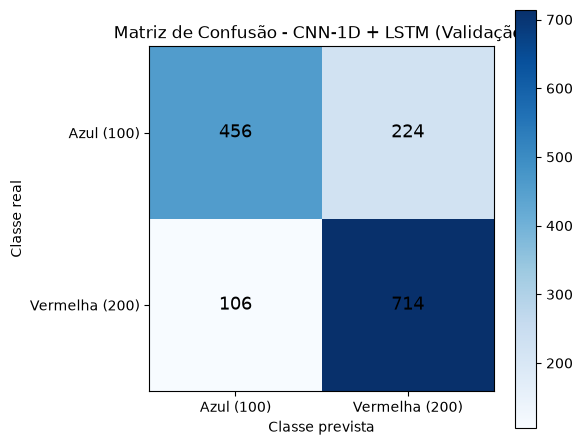

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calcula a matriz de confusão
cm = confusion_matrix(y_val, y_val_pred)

# Visualização
plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Matriz de Confusão - CNN-1D + LSTM (Validação)")
plt.colorbar()

# Rótulos dos eixos
classes = ["Azul (100)", "Vermelha (200)"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

# Valores dentro das células
for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=13
        )

plt.tight_layout()
plt.show()

### Comparação entre CNN+LSTM e CNN+GRU

As duas arquiteturas híbridas também foram implementadas e avaliadas individualmente.

Agora, serão comparados os resultados da CNN+LSTM e da CNN+GRU, considerando as métricas de desempenho obtidas nos conjuntos de validação e teste.

In [26]:
import pandas as pd

# Resultados da CNN+LSTM
resultados_cnn_lstm = {
    "validacao": {
        "Accuracy": accuracy,
        "F1 Macro": f1_macro,
        "Balanced Accuracy": balanced_acc
    },
    "teste": {
        "Accuracy": accuracy_test,
        "F1 Macro": f1_macro_test,
        "Balanced Accuracy": balanced_acc_test
    }
}

# Resultados da CNN+GRU
resultados_cnn_gru = {
    "validacao": {
        "Accuracy": accuracy_cnn_gru,
        "F1 Macro": f1_macro_cnn_gru,
        "Balanced Accuracy": balanced_acc_cnn_gru
    },
    "teste": {
        "Accuracy": accuracy_test_cnn_gru,
        "F1 Macro": f1_macro_test_cnn_gru,
        "Balanced Accuracy": balanced_acc_test_cnn_gru
    }
}

print("Resultados da CNN+LSTM e CNN+GRU armazenados!")

Resultados da CNN+LSTM e CNN+GRU armazenados!


In [27]:
# Resultados de validação
dados_validacao = {
    "CNN+LSTM": resultados_cnn_lstm["validacao"],
    "CNN+GRU": resultados_cnn_gru["validacao"]
}

df_validacao = pd.DataFrame(dados_validacao).T

# Resultados de teste
dados_teste = {
    "CNN+LSTM": resultados_cnn_lstm["teste"],
    "CNN+GRU": resultados_cnn_gru["teste"]
}

df_teste = pd.DataFrame(dados_teste).T

print("=" * 60)
print("COMPARAÇÃO DOS MODELOS - VALIDAÇÃO")
print("=" * 60)
display(df_validacao.round(4))

print("\n" + "=" * 60)
print("COMPARAÇÃO DOS MODELOS - TESTE")
print("=" * 60)
display(df_teste.round(4))

# Identifica o melhor modelo em cada conjunto
melhor_validacao = df_validacao["F1 Macro"].idxmax()
melhor_teste = df_teste["F1 Macro"].idxmax()

print("\nMINI-RELATÓRIO COMPARATIVO")
print("-" * 60)

print(
    f"Melhor modelo na validação: {melhor_validacao} "
    f"(F1 Macro: {df_validacao.loc[melhor_validacao, 'F1 Macro']:.4f})"
)

print(
    f"Melhor modelo no teste: {melhor_teste} "
    f"(F1 Macro: {df_teste.loc[melhor_teste, 'F1 Macro']:.4f})"
)

COMPARAÇÃO DOS MODELOS - VALIDAÇÃO


,Accuracy,F1 Macro,Balanced Accuracy
CNN+LSTM,0.7800,0.7733,0.7707
CNN+GRU,0.7787,0.7713,0.7686



COMPARAÇÃO DOS MODELOS - TESTE


,Accuracy,F1 Macro,Balanced Accuracy
CNN+LSTM,0.7613,0.7567,0.7554
CNN+GRU,0.7607,0.7559,0.7546



MINI-RELATÓRIO COMPARATIVO
------------------------------------------------------------
Melhor modelo na validação: CNN+LSTM (F1 Macro: 0.7733)
Melhor modelo no teste: CNN+LSTM (F1 Macro: 0.7567)


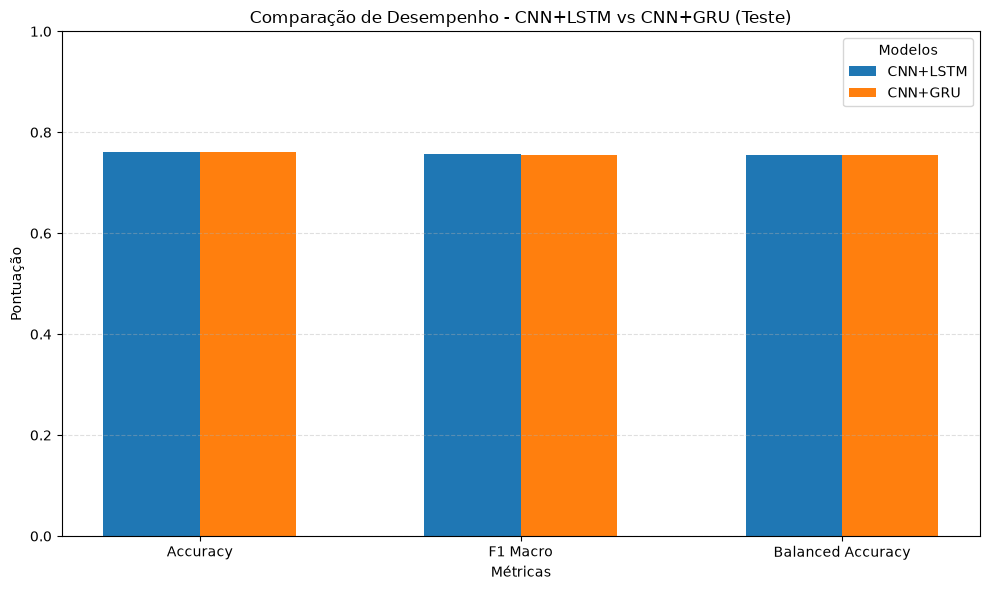

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Métricas
metricas = ["Accuracy", "F1 Macro", "Balanced Accuracy"]

modelos = df_teste.index.tolist()

x = np.arange(len(metricas))
largura = 0.30

plt.figure(figsize=(10, 6))

for i, modelo in enumerate(modelos):
    valores = df_teste.loc[modelo, metricas].values

    plt.bar(
        x + (i - (len(modelos) - 1) / 2) * largura,
        valores,
        largura,
        label=modelo
    )

plt.title("Comparação de Desempenho - CNN+LSTM vs CNN+GRU (Teste)")
plt.ylabel("Pontuação")
plt.xlabel("Métricas")
plt.xticks(x, metricas)
plt.ylim(0, 1)

plt.legend(title="Modelos")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()